## In explore1 , I will explore a small sample dataset like 1-3  April(before nucleaer exit) because small dataset makes problems easier to spot


In [425]:
%pip install pandas
%pip install matplotlib
%pip install seaborn

79748.64s - pydevd: Sending message related to process being replaced timed-out after 5 seconds



[notice] A new release of pip is available: 26.1 -> 26.3
[notice] To update, run: /opt/homebrew/opt/python@3.11/bin/python3.11 -m pip install --upgrade pip
Note: you may need to restart the kernel to use updated packages.


79754.18s - pydevd: Sending message related to process being replaced timed-out after 5 seconds



[notice] A new release of pip is available: 26.1 -> 26.3
[notice] To update, run: /opt/homebrew/opt/python@3.11/bin/python3.11 -m pip install --upgrade pip
Note: you may need to restart the kernel to use updated packages.


79759.65s - pydevd: Sending message related to process being replaced timed-out after 5 seconds



[notice] A new release of pip is available: 26.1 -> 26.3
[notice] To update, run: /opt/homebrew/opt/python@3.11/bin/python3.11 -m pip install --upgrade pip
Note: you may need to restart the kernel to use updated packages.


In [426]:
import pandas as pd
import json
import matplotlib.pyplot as plt
import seaborn as sns

In [427]:
with open("/Users/emrekaya/germany_grid_carbon_forecast/data/raw/sample_public_power_2023-04-01_03.json") as f:
    data = json.load(f)

In [428]:
data.keys()

dict_keys(['unix_seconds', 'production_types', 'deprecated'])

In [429]:
len(data["unix_seconds"])

288

In [430]:
data["unix_seconds"][0] 
# the output is 1680300000 seconds and it is 2023-02-31 22:00:00 UTC

1680300000

In [431]:
data["unix_seconds"][1] - data["unix_seconds"][0] 
# here is the proof, 900 sec is 15 min .
# It is 15 because the source provide report generation data every 15 min, like they divided 4 period 1 hour.
# I am going to fix timezone.

900

In [432]:
len(data["production_types"])

22

In [433]:
data["production_types"][0].keys()

dict_keys(['name', 'data'])

In [434]:
cols = {}

for source in data["production_types"]:
    print(source["name"])
    
    cols[source["name"]] = source["data"]
 # there are 22 production types I ll use generation columns because  formul have to use production columns.

Hydro pumped storage consumption
Cross border electricity trading
Nuclear
Hydro Run-of-River
Biomass
Fossil brown coal / lignite
Fossil hard coal
Fossil oil
Fossil coal-derived gas
Fossil gas
Geothermal
Hydro water reservoir
Hydro pumped storage
Others
Waste
Wind offshore
Wind onshore
Solar
Load
Residual load
Renewable share of load
Renewable share of generation


In [435]:
df = pd.DataFrame(cols)

In [436]:
len(cols)

22

In [437]:
df.shape

(288, 22)

In [438]:
df.head()

,Hydro pumped storage consumption,Cross border electricity trading,Nuclear,Hydro Run-of-River,Biomass,Fossil brown coal / lignite,Fossil hard coal,Fossil oil,Fossil coal-derived gas,Fossil gas,...,Hydro pumped storage,Others,Waste,Wind offshore,Wind onshore,Solar,Load,Residual load,Renewable share of load,Renewable share of generation
0,-835.4,-2030.2,2790.8,2116.8,4326.2,6166.6,1664.7,306.1,671.0,2466.4,...,781.3,196.8,1116.0,3787.9,19412.4,0.0,45526.8,22326.5,66.4,67.0
1,-204.8,-2030.0,2792.2,2111.5,4315.4,6015.3,1660.0,306.1,685.4,2419.8,...,335.4,196.5,1104.3,3758.8,19734.3,0.0,45045.0,21551.9,67.7,67.5
2,-606.5,-2054.4,2791.6,2109.4,4296.4,5792.5,1646.7,306.1,685.4,2381.6,...,166.0,196.8,1137.9,3696.0,19950.8,0.0,44471.5,20824.6,68.8,68.0
3,-1012.6,-2047.9,2792.9,2111.4,4294.2,5495.4,1651.9,306.1,704.5,2391.7,...,204.3,196.9,1154.1,3569.6,20174.7,0.0,44017.2,20272.9,69.8,68.5
4,-445.0,-2926.7,2787.9,2107.2,4270.7,5363.6,1631.2,306.1,716.2,2339.5,...,557.6,196.7,1154.0,3546.8,20319.2,0.0,43388.0,19522.0,71.1,68.9


In [439]:
# fixing timezone ,UTC
df.index = pd.to_datetime(data["unix_seconds"],unit="s",utc=True)

In [440]:
#cheching dates
df.index[0]

Timestamp('2023-03-31 22:00:00+0000', tz='UTC')

In [441]:
df.index[-1]

Timestamp('2023-04-03 21:45:00+0000', tz='UTC')

In [442]:
#there is no duplicates
df.index.is_unique

True

In [443]:
df.index.diff().value_counts()

0 days 00:15:00    287
Name: count, dtype: int64

Generation columns for formul

In [444]:
# generate columns 16
generate_columns = [
    "Nuclear",
    "Hydro Run-of-River",
    "Biomass",
    "Fossil brown coal / lignite",
    "Fossil hard coal",
    "Fossil oil",
    "Fossil coal-derived gas",
    "Fossil gas",
    "Geothermal",
    "Hydro water reservoir",
    "Hydro pumped storage",
    "Others",
    "Waste",
    "Wind offshore",
    "Wind onshore",
    "Solar",
]

In [445]:
gen_col = df[generate_columns]

In [ ]:
gen_col.shape

(288, 16)

In [447]:
gen_col.head()

,Nuclear,Hydro Run-of-River,Biomass,Fossil brown coal / lignite,Fossil hard coal,Fossil oil,Fossil coal-derived gas,Fossil gas,Geothermal,Hydro water reservoir,Hydro pumped storage,Others,Waste,Wind offshore,Wind onshore,Solar
2023-03-31 22:00:00+00:00,2790.8,2116.8,4326.2,6166.6,1664.7,306.1,671.0,2466.4,9.9,40.8,781.3,196.8,1116.0,3787.9,19412.4,0.0
2023-03-31 22:15:00+00:00,2792.2,2111.5,4315.4,6015.3,1660.0,306.1,685.4,2419.8,9.9,35.7,335.4,196.5,1104.3,3758.8,19734.3,0.0
2023-03-31 22:30:00+00:00,2791.6,2109.4,4296.4,5792.5,1646.7,306.1,685.4,2381.6,9.9,19.2,166.0,196.8,1137.9,3696.0,19950.8,0.0
2023-03-31 22:45:00+00:00,2792.9,2111.4,4294.2,5495.4,1651.9,306.1,704.5,2391.7,9.9,27.1,204.3,196.9,1154.1,3569.6,20174.7,0.0
2023-03-31 23:00:00+00:00,2787.9,2107.2,4270.7,5363.6,1631.2,306.1,716.2,2339.5,9.9,73.4,557.6,196.7,1154.0,3546.8,20319.2,0.0


In [448]:
gen_col.isna().sum()

Nuclear                        0
Hydro Run-of-River             0
Biomass                        0
Fossil brown coal / lignite    0
Fossil hard coal               0
Fossil oil                     0
Fossil coal-derived gas        0
Fossil gas                     0
Geothermal                     0
Hydro water reservoir          0
Hydro pumped storage           0
Others                         0
Waste                          0
Wind offshore                  0
Wind onshore                   0
Solar                          0
dtype: int64

In [449]:
gen_col.describe()
# outlier checking
# there is 0 in solar but is not problem because in day there is night also that's why one of the quarter is 0.
# there is no negative values
# no nulls

,Nuclear,Hydro Run-of-River,Biomass,Fossil brown coal / lignite,Fossil hard coal,Fossil oil,Fossil coal-derived gas,Fossil gas,Geothermal,Hydro water reservoir,Hydro pumped storage,Others,Waste,Wind offshore,Wind onshore,Solar
count,288.000000,288.000000,288.000000,288.000000,288.000000,288.000000,288.000000,288.000000,288.000000,288.000000,288.000000,288.000000,288.000000,288.000000,288.000000,288.000000
mean,2780.997917,1909.259722,4447.202431,7672.699306,3107.473264,306.098264,638.025347,3471.066667,10.718056,79.260069,1187.542014,215.884375,1028.649306,3458.005556,17658.707639,5532.953125
std,8.593239,110.453367,187.589065,2691.728031,1891.239519,0.178741,46.665374,1667.911090,1.391245,56.851876,1763.167136,32.203836,58.678029,2174.643658,5430.690616,7695.323228
min,2758.300000,1726.800000,4174.500000,4955.300000,1599.800000,304.600000,525.000000,2126.100000,9.100000,15.000000,0.500000,183.100000,896.900000,125.400000,8048.500000,0.000000
25%,2773.575000,1809.200000,4284.675000,5207.175000,1952.725000,306.100000,598.300000,2221.875000,9.800000,35.075000,153.425000,189.700000,988.225000,1563.900000,11962.075000,0.000000
50%,2780.200000,1890.950000,4406.950000,6160.000000,2310.000000,306.100000,639.450000,2424.000000,10.200000,62.650000,308.100000,203.850000,1019.800000,3466.250000,17681.800000,411.750000
75%,2787.925000,2005.175000,4570.700000,10282.600000,3706.925000,306.100000,676.500000,4373.200000,11.200000,114.300000,1361.400000,233.850000,1067.675000,5276.000000,22527.675000,9589.175000
max,2798.300000,2116.800000,4905.600000,12705.200000,8486.700000,307.500000,717.300000,7765.900000,13.900000,381.400000,7550.000000,290.000000,1167.800000,7644.900000,27151.100000,26572.600000


In [450]:
gen_col.dtypes

Nuclear                        float64
Hydro Run-of-River             float64
Biomass                        float64
Fossil brown coal / lignite    float64
Fossil hard coal               float64
Fossil oil                     float64
Fossil coal-derived gas        float64
Fossil gas                     float64
Geothermal                     float64
Hydro water reservoir          float64
Hydro pumped storage           float64
Others                         float64
Waste                          float64
Wind offshore                  float64
Wind onshore                   float64
Solar                          float64
dtype: object

I am going to convert time 15 min data to hourly means because It has to match open meteo , open meteo provides data hourly and it would be hard do merge with 15 min that's why hour is more manageable.

Also, my project target is forecasting when electricity will be the cleanest tomorrow, so people can use it at those hours.

In [451]:
gen_hourly = gen_col.resample("1h").mean()

In [452]:
gen_hourly.shape

(72, 16)

In [453]:
gen_hourly.head()

,Nuclear,Hydro Run-of-River,Biomass,Fossil brown coal / lignite,Fossil hard coal,Fossil oil,Fossil coal-derived gas,Fossil gas,Geothermal,Hydro water reservoir,Hydro pumped storage,Others,Waste,Wind offshore,Wind onshore,Solar
2023-03-31 22:00:00+00:00,2791.875,2112.275,4308.050,5867.450,1655.825,306.1,686.575,2414.875,9.900,30.700,371.750,196.750,1128.075,3703.075,19818.050,0.00
2023-03-31 23:00:00+00:00,2785.225,2102.425,4250.225,5181.100,1618.025,306.1,703.750,2286.550,10.025,38.300,236.400,196.675,1151.875,3564.650,20629.325,0.00
2023-04-01 00:00:00+00:00,2785.850,2089.100,4197.725,5035.850,1603.300,306.1,664.625,2219.950,10.175,37.650,129.725,190.950,1150.100,3709.475,21231.400,0.00
2023-04-01 01:00:00+00:00,2789.050,2074.450,4182.950,4974.075,1610.500,306.1,674.750,2224.825,10.200,23.900,83.275,189.200,1147.175,4170.125,21692.800,0.00
2023-04-01 02:00:00+00:00,2793.475,2065.800,4192.125,5053.475,1616.450,306.1,666.875,2229.675,10.150,29.275,82.500,189.275,1106.300,4527.950,22136.400,1.45


In [454]:
print(gen_col.shape, gen_hourly.shape) 
# 288 / 4 = 72 

(288, 16) (72, 16)


In [455]:
gen_col.index[:5] # 15 min period

DatetimeIndex(['2023-03-31 22:00:00+00:00', '2023-03-31 22:15:00+00:00',
               '2023-03-31 22:30:00+00:00', '2023-03-31 22:45:00+00:00',
               '2023-03-31 23:00:00+00:00'],
              dtype='datetime64[us, UTC]', freq=None)

In [456]:
gen_hourly.index[:5] # 1 hour 

DatetimeIndex(['2023-03-31 22:00:00+00:00', '2023-03-31 23:00:00+00:00',
               '2023-04-01 00:00:00+00:00', '2023-04-01 01:00:00+00:00',
               '2023-04-01 02:00:00+00:00'],
              dtype='datetime64[us, UTC]', freq='h')

In [457]:
#manuel control 
print(gen_col.iloc[56:60]["Solar"].mean()) # 14 * 4 = 56 and + 4 row for the quarters 00,15,30,45 it means 56,57,58,59 
print(gen_hourly.iloc[14]["Solar"])

# both of results are matching. 

9188.125
9188.125


Emission Factors

In [458]:
# PLACEHOLDER values (gCO2/kWh), values are examples , real values will fill after with sources.
EF = {
    "Nuclear": 10,
    "Hydro Run-of-River": 10,
    "Biomass": 250,
    "Fossil brown coal / lignite": 1000,
    "Fossil hard coal": 1000,
    "Fossil oil": 700,
    "Fossil coal-derived gas": 700,
    "Fossil gas": 400,
    "Geothermal": 30,
    "Hydro water reservoir": 10,
    "Hydro pumped storage": 250,
    "Others": 250,
    "Waste": 250,
    "Wind offshore": 10,
    "Wind onshore": 10,
    "Solar": 50,
}
print(set(EF) == set(gen_col)) # match checked

True


In [459]:
ef = pd.Series(EF)

In [ ]:
ef.head

<bound method NDFrame.head of Nuclear                          10
Hydro Run-of-River               10
Biomass                         250
Fossil brown coal / lignite    1000
Fossil hard coal               1000
Fossil oil                      700
Fossil coal-derived gas         700
Fossil gas                      400
Geothermal                       30
Hydro water reservoir            10
Hydro pumped storage            250
Others                          250
Waste                           250
Wind offshore                    10
Wind onshore                     10
Solar                            50
dtype: int64>

In [461]:
# compute carbon intensity
# for example: when there is high level wind and sun, CI low(cleaner)
# carbon intensity is target variable of the project.

In [462]:
def compute_ci(gen_hourly, ef):
    numerator = (gen_hourly * ef).sum(axis=1)
    denominator = gen_hourly.sum(axis=1)
    return numerator/denominator

In [463]:
# testing
test_ci = compute_ci(gen_hourly, ef)
print(test_ci.shape)

(72,)


In [464]:
print(test_ci.describe())

count     72.000000
mean     284.300858
std       98.179353
min      185.972426
25%      208.843997
50%      233.409197
75%      370.225423
max      509.051858
dtype: float64


In [465]:
# manuel control
row = gen_hourly.iloc[4]
numerator = sum(row[i] * ef[i] for i in gen_col)
denominator = row.sum()

In [466]:
print(numerator/denominator)
print(test_ci.iloc[4])

211.69773189362706
211.69773189362706


<Axes: >

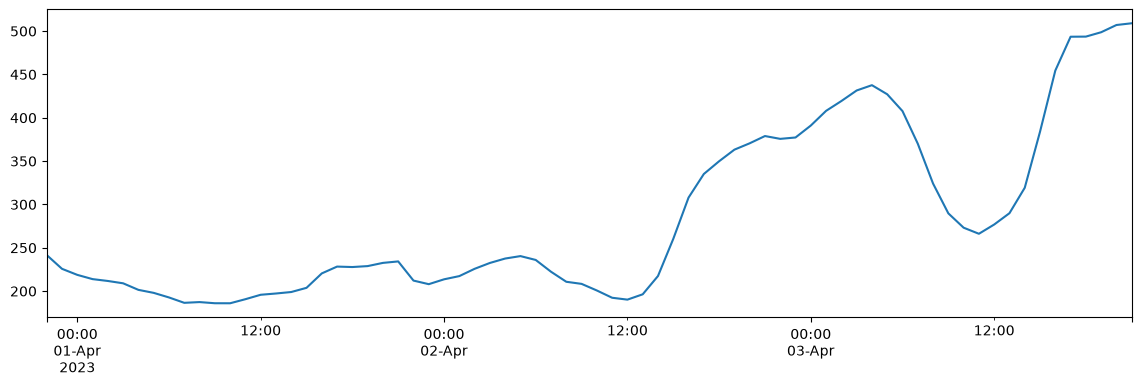

In [467]:
# graph control
test_ci.plot(figsize=(14, 4))
sns.lineplot(test_ci)

In [468]:
# ci is lower around midday and higher at night as what we expected.

In [469]:
# correlation control 
# ci and renawable should neggative correlation
# when renewable increase ci will decrease.

In [470]:
df["Renewable share of generation"].head() # 15 min periods , I ll convert as a hour bc test_ci is hourly

2023-03-31 22:00:00+00:00    67.0
2023-03-31 22:15:00+00:00    67.5
2023-03-31 22:30:00+00:00    68.0
2023-03-31 22:45:00+00:00    68.5
2023-03-31 23:00:00+00:00    68.9
Name: Renewable share of generation, dtype: float64

In [474]:
share_hourly = df["Renewable share of generation"].resample("1h").mean()

In [475]:
share_hourly.head()

2023-03-31 22:00:00+00:00    67.750
2023-03-31 23:00:00+00:00    69.475
2023-04-01 00:00:00+00:00    70.325
2023-04-01 01:00:00+00:00    70.950
2023-04-01 02:00:00+00:00    71.325
Freq: h, Name: Renewable share of generation, dtype: float64

In [476]:
test_ci.corr

<bound method Series.corr of 2023-03-31 22:00:00+00:00    241.625338
2023-03-31 23:00:00+00:00    225.716534
2023-04-01 00:00:00+00:00    218.742736
2023-04-01 01:00:00+00:00    213.842633
2023-04-01 02:00:00+00:00    211.697732
                                ...    
2023-04-03 17:00:00+00:00    493.527535
2023-04-03 18:00:00+00:00    493.662396
2023-04-03 19:00:00+00:00    498.711223
2023-04-03 20:00:00+00:00    507.046556
2023-04-03 21:00:00+00:00    509.051858
Freq: h, Length: 72, dtype: float64>

In [479]:
corrvalue= test_ci.corr(share_hourly)
print(corrvalue)

-0.994478838974232


Text(0, 0.5, 'CI')

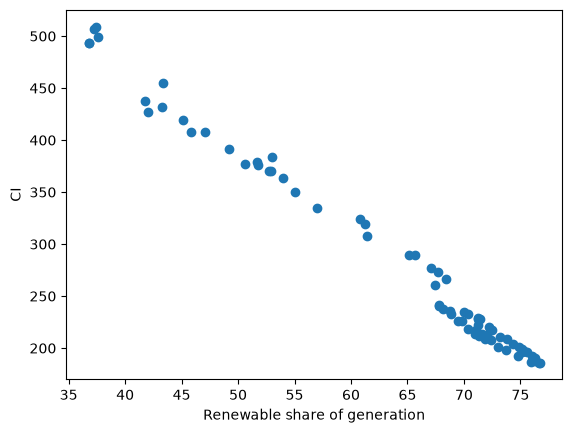

In [ ]:
plt.scatter(share_hourly, test_ci)
plt.xlabel("Renewable share of generation")
plt.ylabel("CI")
# CI and renewable has higly negative corr around -0.99.

In [473]:
# index is a UTC timestamp , for readability i ll add columns like hour, weekdat etc. later.

Findings 

Files: unix_seconds has 288 timestamp ,production_types has 22 source 

Time : UTC ,15 min periods totally 4 period in an hour , no missing and duplicated timestamps in 1 - 3 April. 

In 22 columns 16 of them are production and 6 of them are not generation .

There is no negative values in 1 - 3 April.

Solar minimum is 0 because of the night (there is no sun at night). Fossil oil is stable. (≈306.1)

Aggregated to hourly means. (288,16) to (72,16).